In [1]:
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

---

## Vorverarbeitung der Daten

In [2]:
df = pd.read_csv("data.csv")
df["date"] = pd.to_datetime(df["DateTime"])

# Tarife werden vorerst zusammengelegt, "date" wird dabei als Index übernommen
df = df.groupby("date").agg({"KWH": "sum", "meters": "sum"})

# Normalisierung: Stromverbrauch eines Verbrauchers für jeden Zeitpunkt
df["kwh"] = df["KWH"] / df["meters"]

df = df[["KWH", "kwh", "meters"]]
df

,KWH,kwh,meters
date,,,
2011-11-23 09:00:00,0.569000,0.284500,2
2011-11-23 09:30:00,0.561000,0.280500,2
2011-11-23 10:00:00,0.920000,0.153333,6
2011-11-23 10:30:00,0.588000,0.098000,6
2011-11-23 11:00:00,0.772000,0.110286,7
...,...,...,...
2014-02-27 22:00:00,1494.603000,0.299760,4986
2014-02-27 22:30:00,1422.109001,0.285163,4987
2014-02-27 23:00:00,1258.090000,0.252274,4987


---

## Datenbereinigung

Im Datensatz sind fehlerhaft Datenpunkte enthalten, bei denen kein Verbraucher geschaltet ist und die Messungen außerhalb dem 30-Minuten-Taktes liegen.

In [3]:
# Prüfung auf Datenpunkte mit keinem Verbrauch
display(df.loc[(df["KWH"] == 0)])

# Falls die Prüfungen nichts zurückliefern, können die fehlerhaften Datenpunkte entfernt werden
# Prüfung auf korrekte Datenpunkte mit keinem Verbrauch
display(df.loc[(df["KWH"] == 0) & ((df.index.minute % 30 == 0) & (df.index.second == 0))])
# Prüfung auf korrekte Datenpunkte außerhalb des 30-Minuten-Taktes
display(df.loc[~(df["KWH"] == 0) & ~((df.index.minute % 30 == 0) & (df.index.second == 0))])

# Durch .asfreq() fallen die fehlerhaften Datenpunkte weg
df = df.sort_index().asfreq("30min")
df["kwh"].isna().sum()

,KWH,kwh,meters
date,,,
2012-12-18 15:13:26,0.0,NaN,0
2012-12-18 15:13:27,0.0,NaN,0
2012-12-18 15:13:28,0.0,NaN,0
2012-12-18 15:13:29,0.0,NaN,0
2012-12-18 15:13:30,0.0,NaN,0
...,...,...,...
2013-07-05 12:54:31,0.0,NaN,0
2013-07-05 13:15:05,0.0,NaN,0
2013-09-20 18:24:09,0.0,NaN,0


,KWH,kwh,meters
date,,,


,KWH,kwh,meters
date,,,


np.int64(0)

---

## Untersuchung der Zeitreihe auf Trend, Saisonalität und Residuum

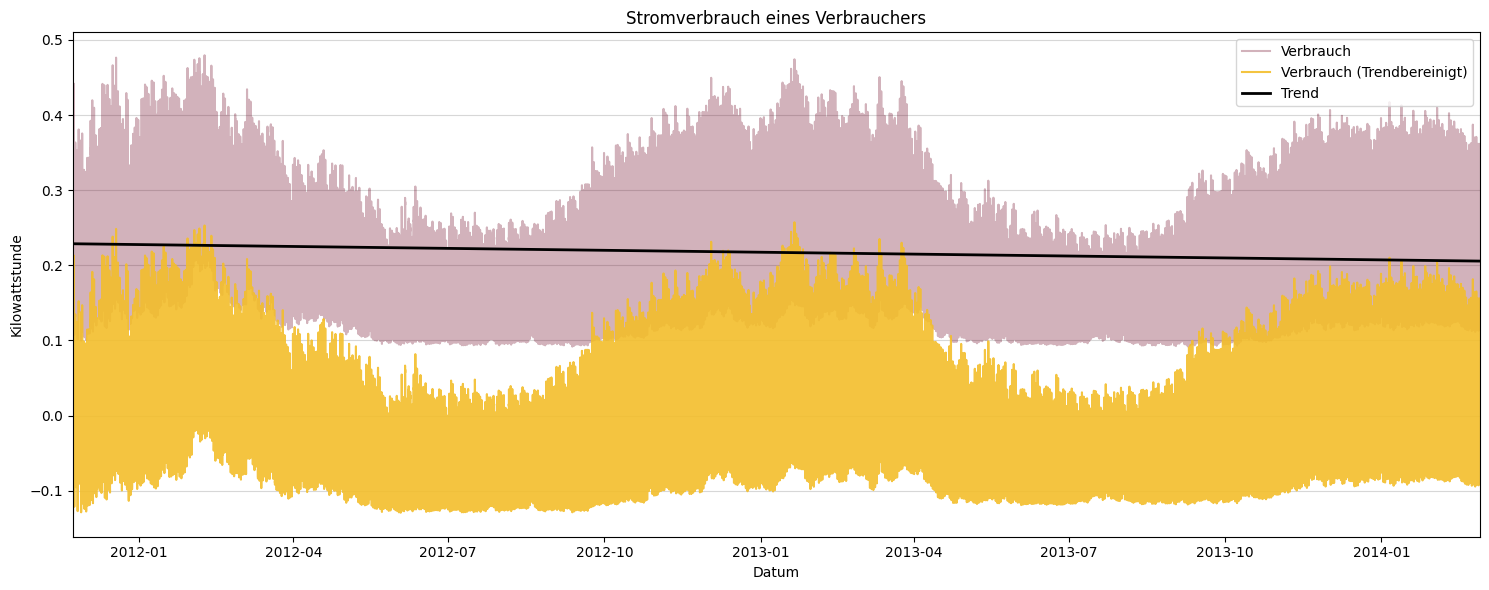

In [4]:
def analyse_trend(df: pd.DataFrame) -> pd.DataFrame:
    # Berechnung des linearen Trends der Zeitreihe
    x = mdates.date2num(df.index)
    p = np.poly1d(np.polyfit(x, df["kwh"], 1))
    df["kwh_trend"] = p(x)

    # Der Stromverbrauch bereinigt vom Trend
    df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]

    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.3, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.9, label="Verbrauch (Trendbereinigt)")
    ax.plot(df.index, df["kwh_trend"], color="#000000", alpha=1, linewidth=2, label="Trend")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    return df


df = analyse_trend(df)

<font color="orange">
Erkenntnisse: Es ist ein schwach fallender Trend zu erkennen - Stromverbrauch nimmt über die Zeit ab (auch, wenn man als Zeitraum volle Jahre nimmt, also vom 01.01.2012 bis 01.01.2014).
</font>

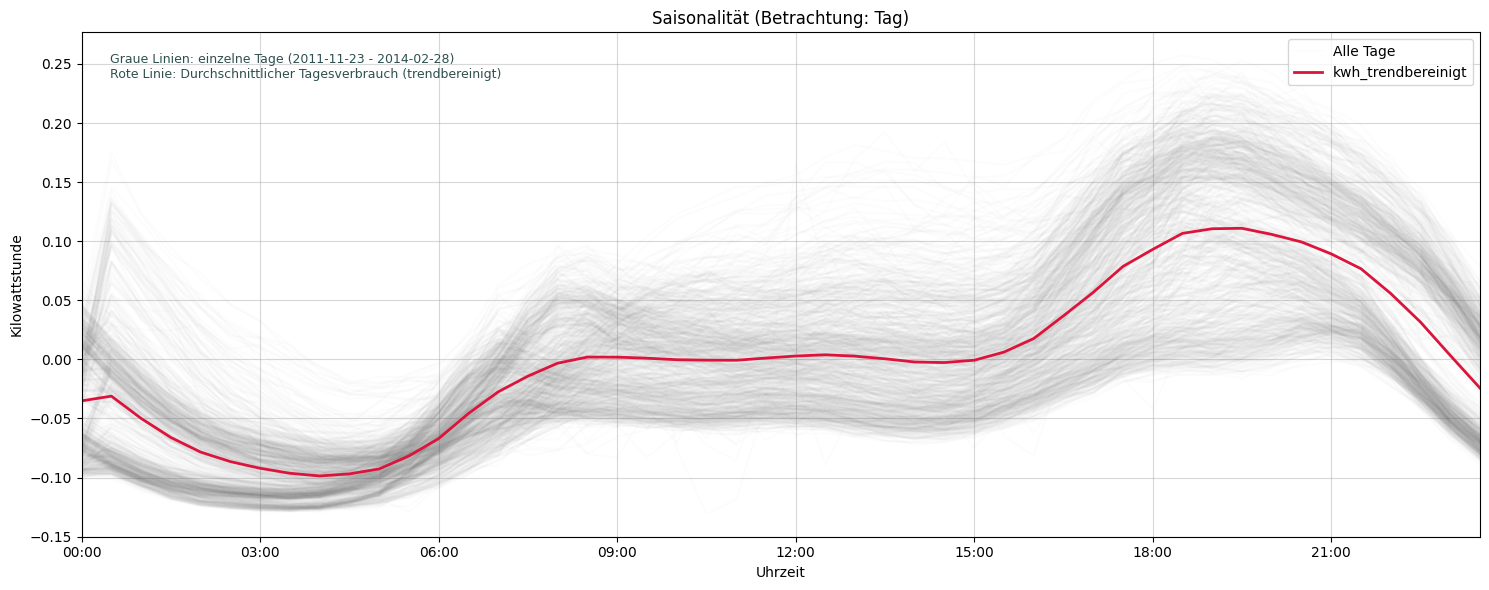

In [5]:
def analyse_seasonality(df: pd.DataFrame) -> pd.DataFrame:
    df["focus"] = df.index.hour * 2 + (df.index.minute // 30)  # Fokus auf einen Tag setzen

    # Der Mittelwert aller 30-Minuten Intervalle eines Tages
    seasonal = df.groupby("focus")["kwh_trendbereinigt"].mean()

    _, ax = plt.subplots(figsize=(15, 6))

    # Verbrauch aller Tage zur Veranschaulichung
    df["pivot_date"] = df.index.date  # Pivot arbeitet effizienter als die for-Schleife, die Logik ist aber die selbe
    pivot_data = df.pivot_table(index="focus", columns="pivot_date", values="kwh_trendbereinigt")

    lines = ax.plot(pivot_data, color="gray", alpha=0.02)
    if lines:
        lines[0].set_label("Alle Tage")

    seasonal.plot(ax=ax, color="crimson", linewidth=2)
    ax.set(
        title="Saisonalität (Betrachtung: Tag)",
        xlabel="Uhrzeit",
        ylabel="Kilowattstunde",
    )

    ax.text(
        0.02,
        0.96,
        f"Graue Linien: einzelne Tage ({pivot_data.columns.min()} - {pivot_data.columns.max()})\nRote Linie: Durchschnittlicher Tagesverbrauch (trendbereinigt)",
        transform=ax.transAxes,
        fontsize=9,
        color="darkslategray",
        verticalalignment="top",
    )

    ax.set_xticks(range(0, 48, 6))
    ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 3)])
    ax.grid(axis="both", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # .transform berechnet den Mittelwert pro Gruppe und weist ihn jedem Datenpunkt der Gruppe zu
    df["kwh_trendbereinigt_saison"] = df.groupby("focus")["kwh_trendbereinigt"].transform("mean")
    return df.drop(columns=["focus", "pivot_date"])


df = analyse_seasonality(df)

<font color="orange">
Erkenntnisse: Wie erwartet fällt der Stromverbrauch nachts sehr stark, nimmt im Laufe des Mittags zu und erreicht seinen Höhepunkt abends, wenn jeder wieder zu Hause ist.
</font>

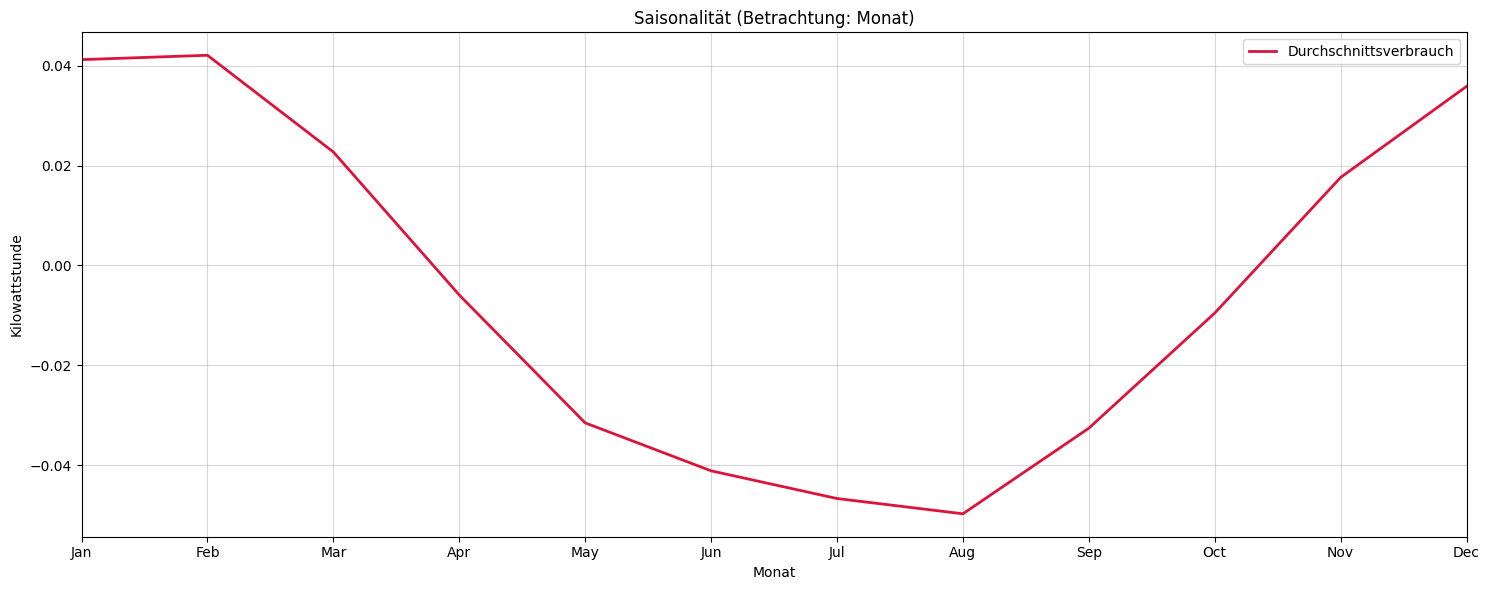

In [6]:
# Ergänzend
def analyse_seasonality_year(df: pd.DataFrame) -> None:
    df_year = df.copy()

    # Fokus auf ein Jahr setzen
    df_year["focus"] = df_year.index.month

    seasonal = df_year.groupby("focus")["kwh_trendbereinigt"].mean()

    _, ax = plt.subplots(figsize=(15, 6))

    seasonal.plot(ax=ax, color="crimson", alpha=1, label="Durchschnittsverbrauch", linewidth=2)  ##031E81 Ursprüngliche Farbe
    ax.set(
        title="Saisonalität (Betrachtung: Monat)",
        xlabel="Monat",
        ylabel="Kilowattstunde",
    )
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(pd.Series(range(1, 13)).map(lambda x: pd.to_datetime(x, format="%m").strftime("%b")))
    ax.grid(axis="both", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()


analyse_seasonality_year(df)

<font color="orange">
Erkenntnisse: Im den Wintermonaten wird deutlich mehr Strom verbraucht als im Sommer.
</font>

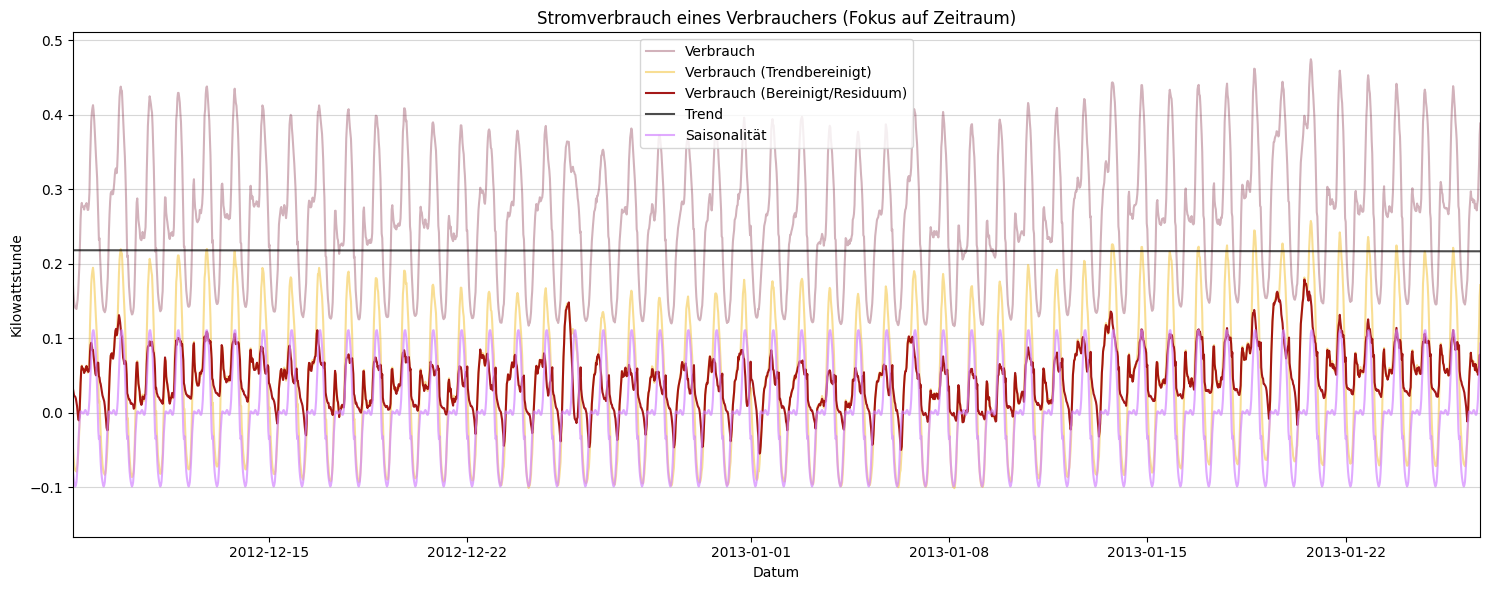

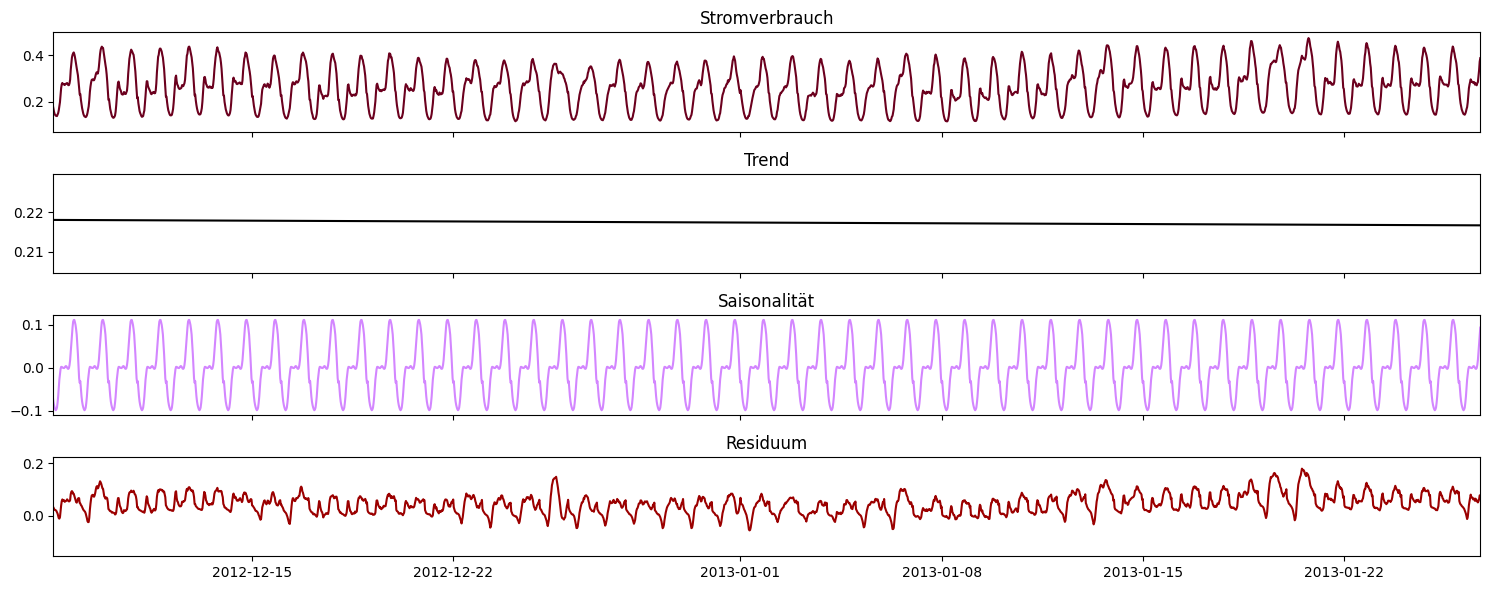

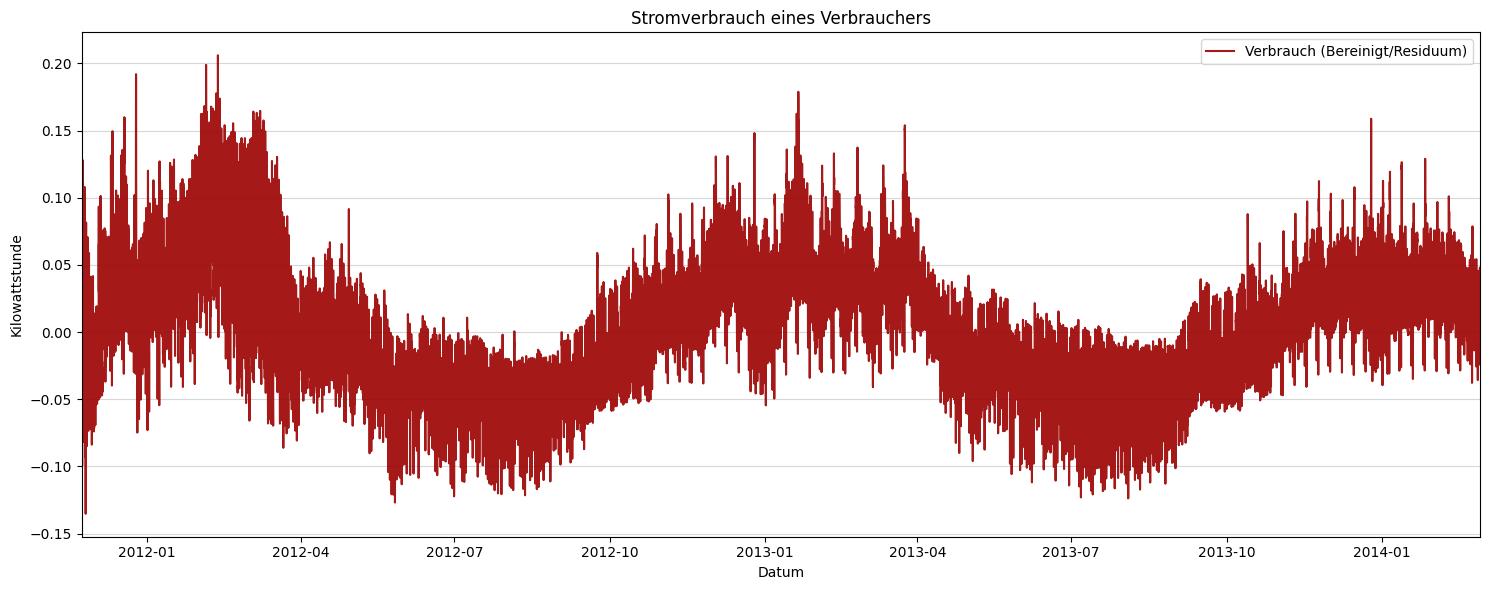

In [7]:
def analyse_cleaned(df: pd.DataFrame) -> pd.DataFrame:
    _, ax = plt.subplots(figsize=(15, 6))

    # Berechnung der bereinigte Zeitreihe bzw. dem Residuum/Rest
    df["kwh_bereinigt"] = df["kwh_trendbereinigt"] - df["kwh_trendbereinigt_saison"]

    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.3, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.5, label="Verbrauch (Trendbereinigt)")
    ax.plot(df.index, df["kwh_bereinigt"], color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    ax.plot(df.index, df["kwh_trend"], color="#000000FF", alpha=0.7, label="Trend")
    ax.plot(df.index, df["kwh_trendbereinigt_saison"], color="#D386FF", alpha=0.7, label="Saisonalität")
    ax.set(
        title="Stromverbrauch eines Verbrauchers (Fokus auf Zeitraum)",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    # Begrenzung auf Zeitraum zur besseren Lesbarkeit
    ax.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # Getrennte Plots
    _, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(df["kwh_trend"], color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(df["kwh_trendbereinigt_saison"], color="#D386FF")
    ax[2].set_title("Saisonalität")

    ax[3].plot(df["kwh_bereinigt"], color="#9B0000")
    ax[3].set_title("Residuum")

    plt.tight_layout()
    plt.show()

    # Residuum der gesamten Zeitreihe
    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(df.index, df["kwh_bereinigt"], color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()
    return df


df = analyse_cleaned(df)

---

## Verwendung von STL

Unsere manuelle Zerlegung basiert auf einem einfachen additiven Modell, welches einige Ungenauigkeiten aufweist: Ein linearer Trend ist unzureichend und eine einmalige Tages-Mittelung erfasst keine Schwankungen in der Saisonalität über die Zeit.

STL verwendet einen iterativen Prozess, der Trend und Saisonalität wechselseitig verfeinert. Die Loess-Glättung ist dabei robuster gegenüber Ausreißern, und die Saisonalitätskomponente kann sich über den Beobachtungszeitraum hinweg verändern. 

Das Residuum ist dadurch sauberer isoliert und repräsentiert tatsächlich nur den zufälligen Rest.

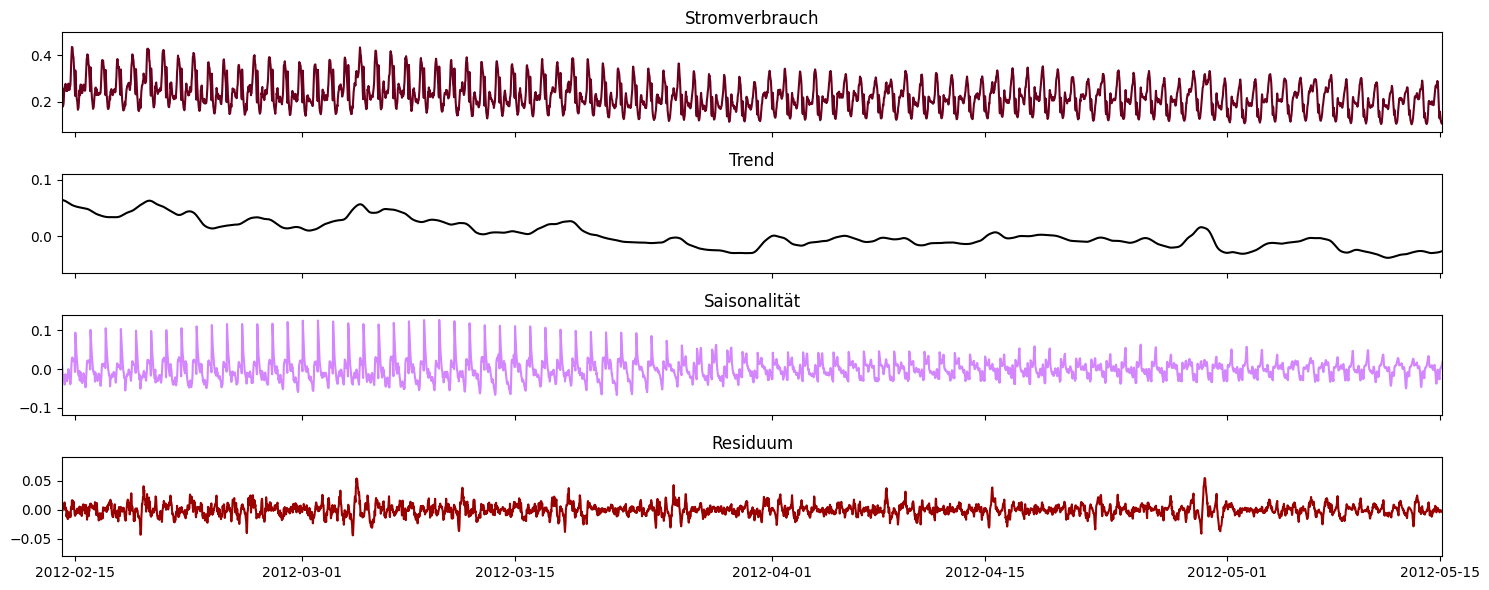

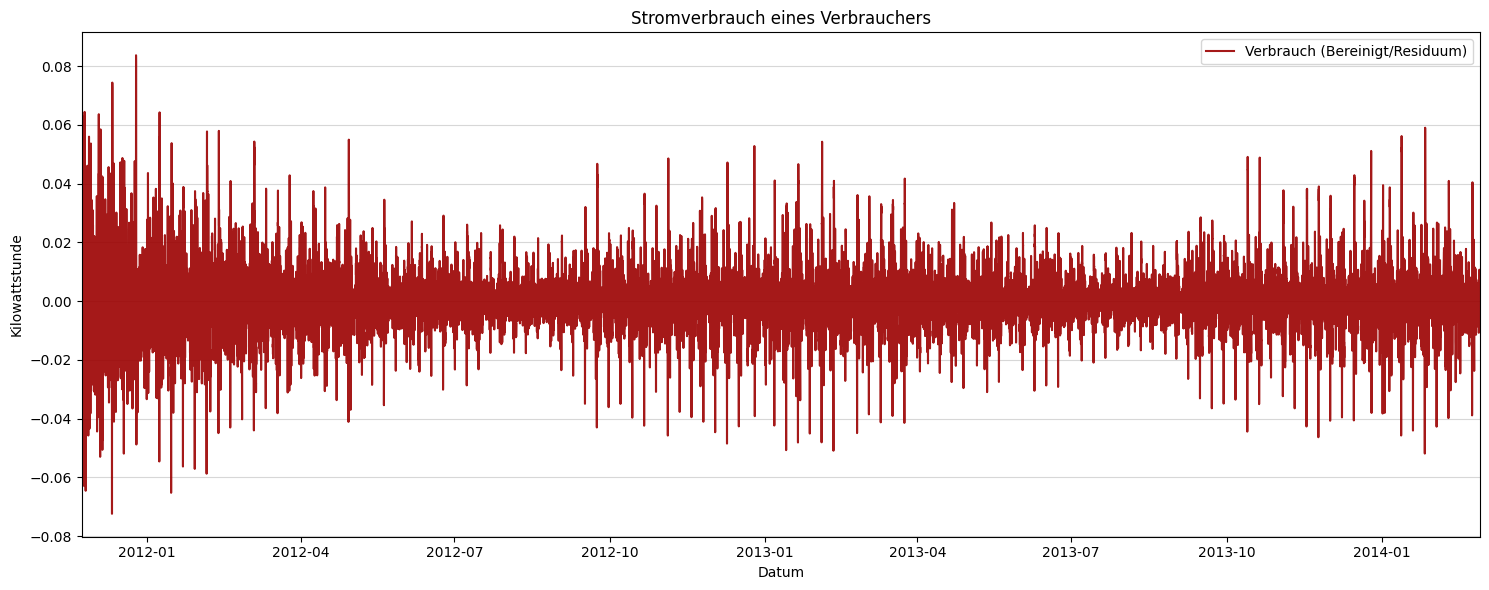

In [8]:
from statsmodels.tsa.seasonal import STL


def plot_STL(df: pd.DataFrame) -> pd.DataFrame:
    decomposition = STL(
        df["kwh_bereinigt"],
        period=48,
    )
    decomposition = decomposition.fit()

    _, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.10), pd.Series(df.index).quantile(0.21))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(decomposition.trend, color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(decomposition.seasonal, color="#D386FF")
    ax[2].set_title("Saisonalität")

    ax[3].plot(decomposition.resid, color="#9B0000")
    ax[3].set_title("Residuum")

    plt.tight_layout()
    plt.show()

    # Residuum der gesamten Zeitreihe
    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(df.index, decomposition.resid, color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    return decomposition


decomposition = plot_STL(df)

In [9]:
# Im Folgendem verwenden wir die berechneten Werte der STL-Methode
df["kwh_trend"] = decomposition.trend
df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]
df["kwh_trendbereinigt_saison"] = decomposition.seasonal
df["kwh_bereinigt"] = decomposition.resid

In [10]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(df["kwh_bereinigt"], order=(1, 0, 1))
result = model.fit()

final_residuals = result.resid

c:\Users\Sven\Documents\Studies\semester-3\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


<Axes: xlabel='date'>

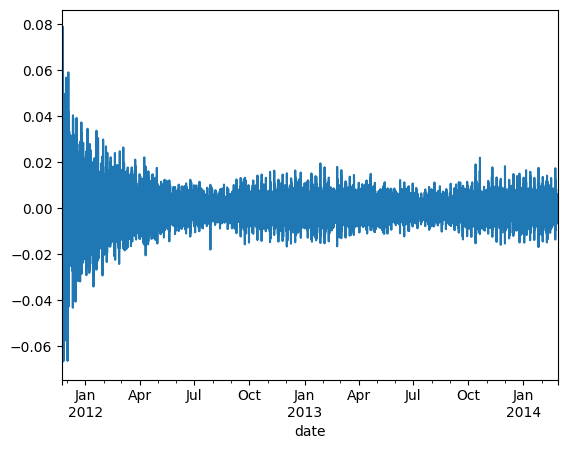

In [11]:
final_residuals.plot()

---

## Autokorrelation und Partielle Autokorrelation

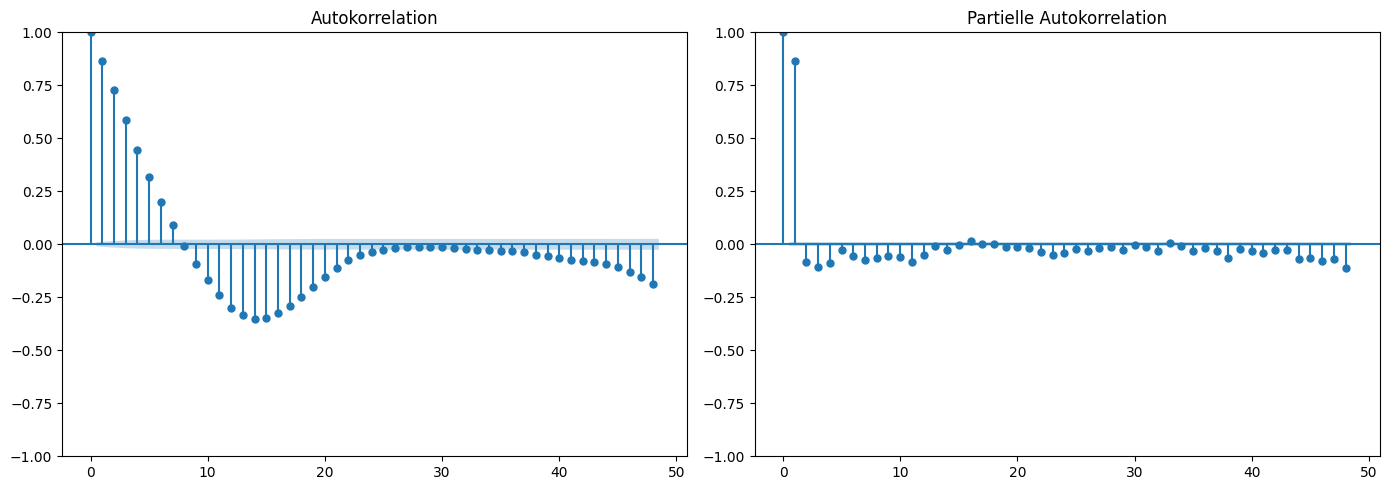

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

_, ax = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(df["kwh_bereinigt"], lags=48, ax=ax[0])
ax[0].set_title("Autokorrelation")

plot_pacf(df["kwh_bereinigt"], lags=48, ax=ax[1])
ax[1].set_title("Partielle Autokorrelation")

plt.tight_layout()
plt.show()

<font color="orange">
Erkenntnisse: Es handelt sich dabei um eine Abhängigkeit jedes Lag auf den vorherigen, wie durch die PACF bestätigt. 
Das Echo der Autokorrelation lässt sich als AR(1)-Prozess erklären, jeder Lag ist von seinem vorherigen abhängig.
</font>


In [13]:
# Funktionen für die Modellanalyse
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from typing import Tuple


def plot_pred(test: pd.DataFrame, pred: np.ndarray, col: str) -> None:
    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(test.index, test[col], color="#6B001E", alpha=0.7, label="Tatsächlicher Verbrauch")
    ax.plot(test.index, pred, color="#0029BC", alpha=1, label="Prognose")

    ax.set(
        title="Prognose 6 Stunden in die Zukunft",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.set_xlim(pd.Series(test.index).quantile(0.0), pd.Series(test.index).quantile(0.1))
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()


def show_metrics(y_test: np.ndarray, pred: np.ndarray, model: LinearRegression, verbose: bool = True) -> Tuple[float, float, float, float]:
    r2 = r2_score(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = root_mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)

    if verbose:
        print(
            f"Regression Intercept: {model.intercept_}\n"
            f"Regression Coefficients: {model.coef_}\n"
            f"R²:\t{r2: .6f}\n"
            f"MSE:\t{mse: .6f}\n"
            f"RMSE:\t{rmse: .6f}\n"
            f"MAE:\t{mae: .6f}\n"
        )

    return r2, mse, rmse, mae

---

## Vorhersage mit Linearer Regression

Zielvariable hier ist zunächst der tatsächliche Verbrauch 6 Stunden in der Zukunft.

Da STL für seine Decompesition auch Daten aus der Zukunft nimmt, würde die Weiterverwendung für das Training von Modellen Data Leakage einführen.

Deshalb werden für die Trainingsdaten wieder auf die manuelle Zerlegung zurückgegriffen.

In [14]:
df_model_a = df.copy()
# Aufteilung der Trainings- und Testdaten
split = int(len(df_model_a) * 0.7)
train = df_model_a.iloc[:split]
test = df_model_a.iloc[split:]

In [15]:
# Trend
x_train = mdates.date2num(train.index)
p = np.poly1d(np.polyfit(x_train, train["kwh"], 1))

train["kwh_trend"] = p(mdates.date2num(train.index))
test["kwh_trend"] = p(mdates.date2num(test.index))  # Extrapolation auf Testdaten

# Trendbereinigung
train["kwh_trendbereinigt"] = train["kwh"] - train["kwh_trend"]
test["kwh_trendbereinigt"] = test["kwh"] - test["kwh_trend"]


# Saisonalität
train["focus"] = train.index.hour * 2 + (train.index.minute // 30)
seasonal = train.groupby("focus")["kwh_trendbereinigt"].mean()  # Nur Train

test["focus"] = test.index.hour * 2 + (test.index.minute // 30)

train["kwh_saison"] = train["focus"].map(seasonal)
test["kwh_saison"] = test["focus"].map(seasonal)  # Mapping, kein Refit


# Residuum
train["kwh_bereinigt"] = train["kwh_trendbereinigt"] - train["kwh_saison"]
test["kwh_bereinigt"] = test["kwh_trendbereinigt"] - test["kwh_saison"]


# Aufteilung der Spalten nach Train und Test
for split_df in [train, test]:
    split_df["kwh_bereinigt_t-1"] = split_df["kwh_bereinigt"].shift(1)
    split_df["kwh_saison_t+12"] = split_df["kwh_saison"].shift(-12)
    split_df["kwh_target"] = split_df["kwh"].shift(-12)

last_row = test.iloc[[-1]].copy()

# Zukunfstwert für die letzte Zeile berechnen
future_time = last_row.index[0] + pd.Timedelta(hours=6)
future_focus = future_time.hour * 2 + (future_time.minute // 30)

last_row["kwh_trend_t+12"] = p(mdates.date2num([future_time]))[0]
last_row["kwh_saison_t+12"] = seasonal.loc[future_focus]

train = train.dropna()
test = test.dropna()
df_model_a = pd.concat([test, last_row])

#### Hinweis zum Shift der Saisonalität:
Die Saison berechnet sich aus den Tagesmittelwerten.
Dem Modell wird durch den Shift mitgegeben wie sich der Zyklus zum Zeitpunkt seiner geplanten Vorhersage ändert.

Würde der aktuelle Zeitpunkt für den Zyklus gewählt werden, würde das Modell z.B. den Morgenzyklus auf den Mittagswert anwenden.

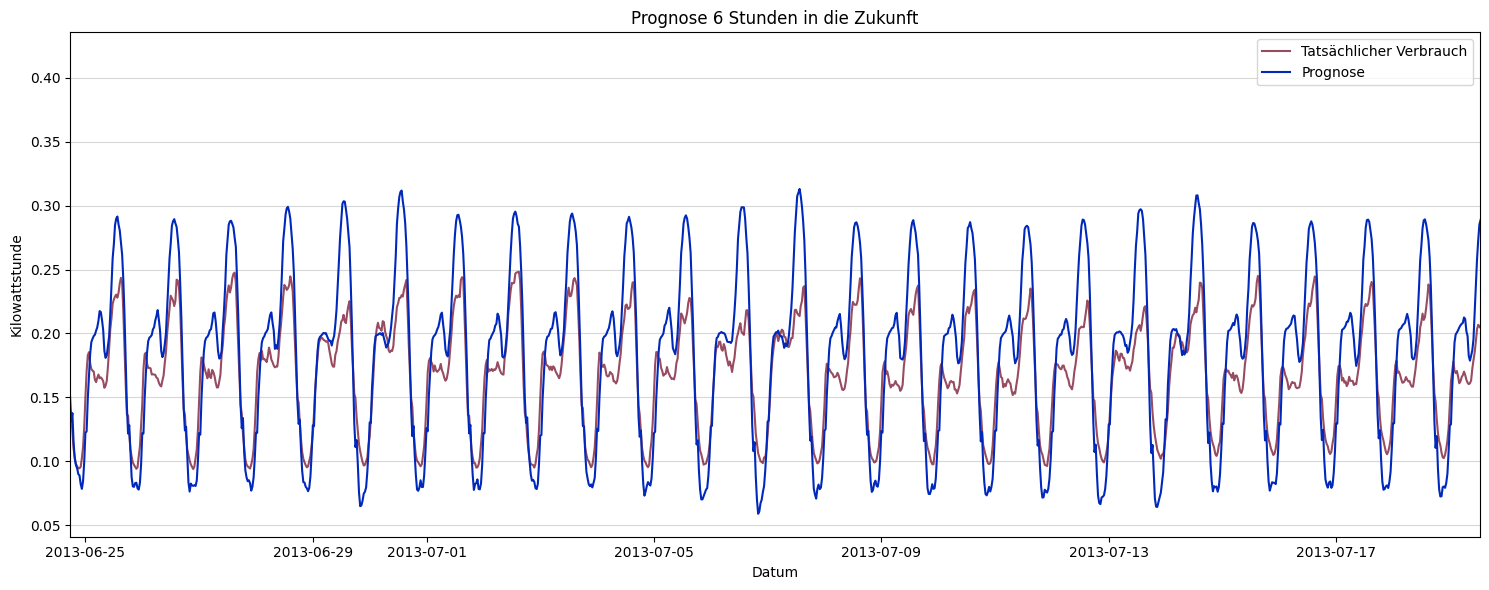

Regression Intercept: -0.0001327351331575355
Regression Coefficients: [ 0.7093596  -0.08036716  1.00052203  0.99978667]
R²:	 0.791968
MSE:	 0.001122
RMSE:	 0.033492
MAE:	 0.027093



In [16]:
# Trainieren des Models
features_a = ["kwh_bereinigt", "kwh_bereinigt_t-1", "kwh_trend", "kwh_saison_t+12"]

X_train_a = train[features_a]
y_train_a = train["kwh_target"]  # Den um 6 Stunden verschobenen Wert nehmen, nicht den Original Wert
model_a = LinearRegression()
model_a.fit(X_train_a, y_train_a)

# Vorhersage auf Testdaten
X_test_a = test[features_a]
y_pred_a = model_a.predict(X_test_a)

plot_pred(test, y_pred_a, "kwh_target")
_ = show_metrics(test["kwh_target"], y_pred_a, model_a)

In [17]:
test["kwh_target"]

date
2013-06-24 17:30:00    0.139908
2013-06-24 18:00:00    0.136840
2013-06-24 18:30:00    0.123115
2013-06-24 19:00:00    0.109820
2013-06-24 19:30:00    0.102670
                         ...   
2014-02-27 16:00:00    0.299760
2014-02-27 16:30:00    0.285163
2014-02-27 17:00:00    0.252274
2014-02-27 17:30:00    0.215284
2014-02-27 18:00:00    0.208997
Freq: 30min, Name: kwh_target, Length: 11906, dtype: float64

<font color="orange">
Erkenntnisse: Das Modell erkennt Saisonalität und Trend gut, hat aber Probleme die Varianz des Residuums genauer einzugrenzen.

Insgesamt liefert das Modell aber gute Prognosen, die nahe der echten Daten liegen.
</font>

---

Als Zielvariable wird nun das Residuum 6 Stunden in der Zukunft verwendet.

Für die eigentliche Vorhersage werden der zuvor berechnete Trend und Saisonalität wieder einberechnet. 

In [18]:
df_model_b = df.copy()
# Train-Test-Split
split = int(len(df_model_b) * 0.7)
train = df_model_b.iloc[:split].copy()
test = df_model_b.iloc[split:].copy()

In [19]:
# Trend
x_train = mdates.date2num(train.index)
p = np.poly1d(np.polyfit(x_train, train["kwh"], 1))

train["kwh_trend"] = p(mdates.date2num(train.index))
test["kwh_trend"] = p(mdates.date2num(test.index))  # Extrapolation

# Trendbereinigung
train["kwh_trendbereinigt"] = train["kwh"] - train["kwh_trend"]
test["kwh_trendbereinigt"] = test["kwh"] - test["kwh_trend"]


# Saisonalität
train["focus"] = train.index.hour * 2 + (train.index.minute // 30)
seasonal = train.groupby("focus")["kwh_trendbereinigt"].mean()

test["focus"] = test.index.hour * 2 + (test.index.minute // 30)

train["kwh_saison"] = train["focus"].map(seasonal)
test["kwh_saison"] = test["focus"].map(seasonal)


# Residuum
train["kwh_bereinigt"] = final_residuals
test["kwh_bereinigt"] = final_residuals


# Aufteilung der Spalten nach Train und Test
for split_df in [train, test]:
    split_df["kwh_bereinigt_t-1"] = split_df["kwh_bereinigt"].shift(1)

    # Trend und Saison bei t+12 – nur für Rekomposition, nicht als Features
    split_df["kwh_trend_t+12"] = split_df["kwh_trend"].shift(-12)
    split_df["kwh_saison_t+12"] = split_df["kwh_saison"].shift(-12)
    # Zielwerte
    split_df["kwh_target_bereinigt"] = split_df["kwh_bereinigt"].shift(-12)
    split_df["kwh_target"] = split_df["kwh"].shift(-12)

last_row = test.iloc[[-1]].copy()


future_time = last_row.index[0] + pd.Timedelta(hours=6)
future_focus = future_time.hour * 2 + (future_time.minute // 30)

last_row["kwh_trend_t+12"] = p(mdates.date2num([future_time]))[0]
last_row["kwh_saison_t+12"] = seasonal.loc[future_focus]

train = train.dropna()
test = test.dropna()

df_model_b = pd.concat([test, last_row])

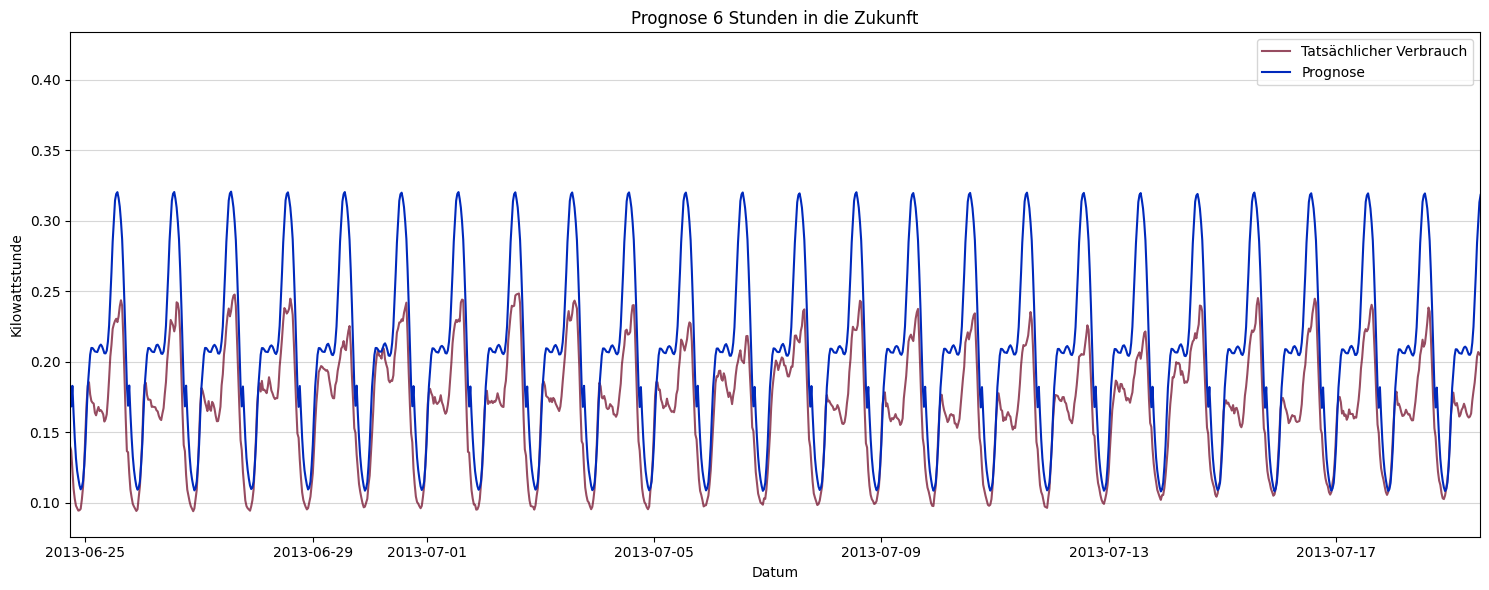

Regression Intercept: -1.5314577056965515e-06
Regression Coefficients: [-0.08902897 -0.06055111]
R²:	 0.654624
MSE:	 0.001862
RMSE:	 0.043154
MAE:	 0.035525



In [20]:
features_b = ["kwh_bereinigt", "kwh_bereinigt_t-1"]
# Training (nur Residuum-Lags als Features)
X_train = train[features_b]
y_train = train["kwh_target_bereinigt"]

model_b = LinearRegression()
model_b.fit(X_train, y_train)

# Vorhersage der Testdaten
X_test_b = test[features_b]
y_pred_residuum = model_b.predict(X_test_b)  # Nur das Residuum wird hier vorhergesagt

# Trend und Saisonalität bei t+12 liegen durch .shift(-12) bereits im test-Index vor
y_pred_b = y_pred_residuum + test["kwh_trend_t+12"] + test["kwh_saison_t+12"]

plot_pred(test, y_pred_b, "kwh_target")
_ = show_metrics(test["kwh_target"], y_pred_b, model_b)

<font color="orange">
Erkenntnisse: Das Modell schätzt auch ohne mitgegebenen Trend und Saisonalität das Residuum beinahe exakt gleich ein.

Ein Grund dafür ist durch die PACF gezeigte Abhängigkeit von nur einen Lag. Bei 12 Lags in die Zukunft geht die Abhängigkeit gegen 0 und ist nur noch unerklärbares Rauschen.

Eine Möglichkeit für bessere Ergebnisse wäre z.B. eine feinere Saisonalitätsbestimmung (Unterscheidung zwischen Wochentagen und Wochenenden).
</font>

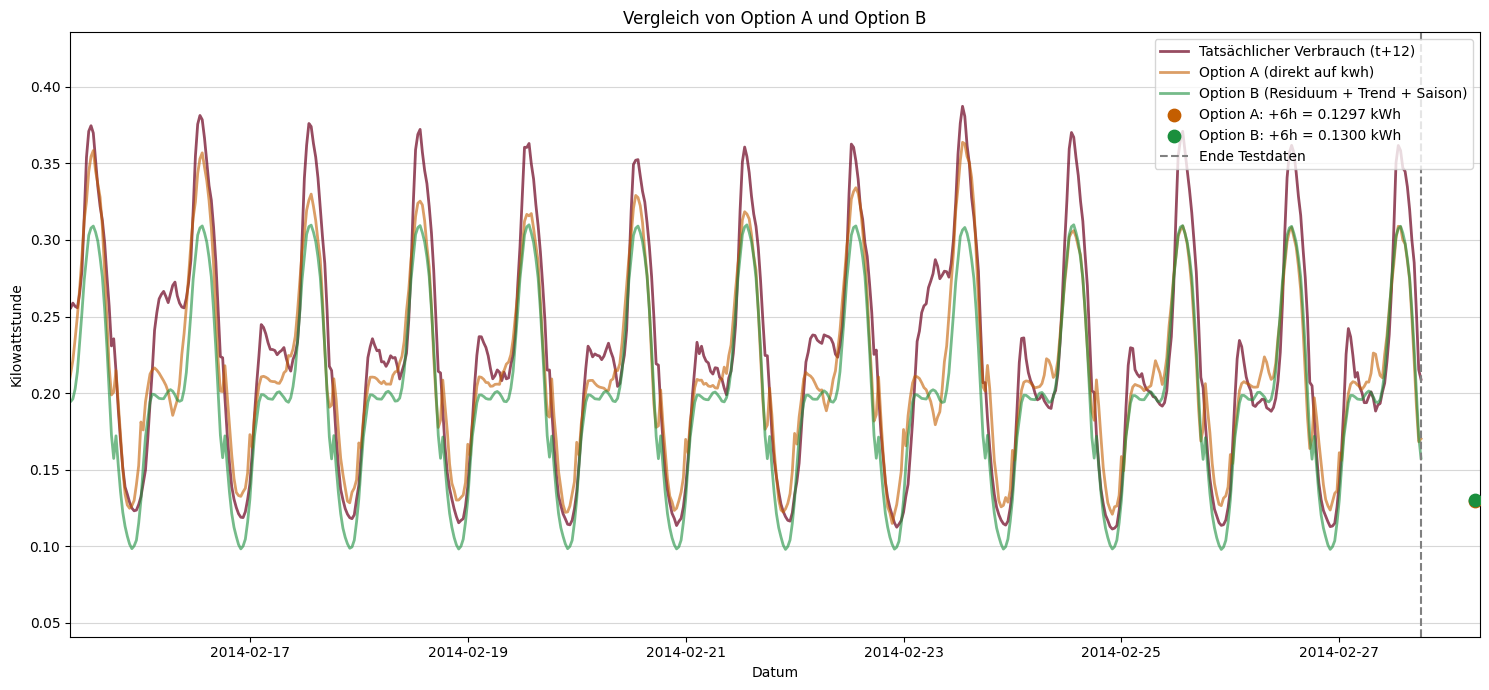

Metrik     Option A   Option B   Verbesserung
---------------------------------------------
R²         0.791968   0.654624      -17.3420%
RMSE       0.033492   0.043154      -28.8488%
MAE        0.027093   0.035525      -31.1230%



In [21]:
# Letzter bekannter Datenpunkt für Zukunftsprognose
last_row_a = df_model_a.iloc[[-1]]
last_row_b = df_model_b.iloc[[-1]]

X_future_a = last_row[features_a]
X_future_b = last_row[features_b]

# Zukunftsprognose Option A
future_pred_a = model_a.predict(X_future_a)[0]
future_time = df_model_a.index[-1] + pd.Timedelta(hours=6)

# Zukunftsprognose Option B
future_residuum_b = model_b.predict(X_future_b)[0]
future_pred_b = future_residuum_b + last_row_b["kwh_trend_t+12"].values[0] + last_row_b["kwh_saison_t+12"].values[0]

_, ax = plt.subplots(figsize=(15, 7))

ax.plot(
    test.index,
    test["kwh_target"],
    color="#6B001E",
    alpha=0.7,
    linewidth=2,
    label="Tatsächlicher Verbrauch (t+12)",
)
ax.plot(test.index, y_pred_a, color="#C45E00", alpha=0.6, linewidth=2, label="Option A (direkt auf kwh)")
ax.plot(test.index, y_pred_b, color="#1A8F3D", alpha=0.6, linewidth=2, label="Option B (Residuum + Trend + Saison)")

ax.scatter(future_time, future_pred_a, color="#C45E00", s=80, zorder=5, label=f"Option A: +6h = {future_pred_a:.4f} kWh")
ax.scatter(future_time, future_pred_b, color="#1A8F3D", s=80, zorder=5, label=f"Option B: +6h = {future_pred_b:.4f} kWh")
ax.axvline(x=test.index[-1], color="gray", linestyle="--", alpha=1, label="Ende Testdaten")

ax.set(
    title="Vergleich von Option A und Option B",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.set_xlim(pd.Series(test.index).quantile(0.95), future_time + pd.Timedelta(hours=1))
ax.grid(axis="y", alpha=0.5)
ax.margins(x=0)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

r2_a, mse_a, rmse_a, mae_a = show_metrics(test["kwh_target"], y_pred_a, model_a, verbose=False)
r2_b, mse_b, rmse_b, mae_b = show_metrics(test["kwh_target"], y_pred_b, model_b, verbose=False)

# Metriken
r2_diff = (r2_b - r2_a) / abs(r2_a) * 100
rmse_diff = (rmse_a - rmse_b) / rmse_a * 100
mae_diff = (mae_a - mae_b) / mae_a * 100

print(
    f"{'Metrik':<8} {'Option A':>10} {'Option B':>10} {'Verbesserung':>14}\n"
    f"{'-' * 45}\n"
    f"{'R²':<8} {r2_a:>10.6f} {r2_b:>10.6f} {r2_diff:>+13.4f}%\n"
    f"{'RMSE':<8} {rmse_a:>10.6f} {rmse_b:>10.6f} {rmse_diff:>+13.4f}%\n"
    f"{'MAE':<8} {mae_a:>10.6f} {mae_b:>10.6f} {mae_diff:>+13.4f}%\n"
)

## Varianzen

In [22]:
# Berechnung der Varianzen
def variances(df: pd.DataFrame):
    df_var = df.copy()

    df_var["trend"] = df_var["kwh_trend"]
    df_var["seasonal"] = df_var["kwh_trendbereinigt_saison"]
    df_var["resid"] = df_var["kwh_bereinigt"]

    variances = df_var[["kwh", "trend", "seasonal", "resid"]].var()
    variances["ryth"] = df_var["seasonal"].var()
    portions = variances / variances["kwh"]

    print(
        f"Von der Varianz der Zeitreihe werden:\n\t{(portions['trend'] * 100):2.1f}% durch den Trend erklärt"
        f"\n\t{(portions['ryth'] * 100):2.1f}% durch die Periodizität erklärt"
        f"\n\t{(portions['resid'] * 100):2.1f}% haben andere Ursachen (Residuum)"
    )


variances(df)

Von der Varianz der Zeitreihe werden:
	24.5% durch den Trend erklärt
	8.5% durch die Periodizität erklärt
	1.7% haben andere Ursachen (Residuum)


## Vergleich beider Tarife

In [23]:
df = pd.read_csv("data.csv")


def prep_data(df: pd.DataFrame, rate: str) -> pd.DataFrame:
    df["date"] = pd.to_datetime(df["DateTime"])
    df = df.loc[df["rate"] == rate]
    df["kwh"] = df["KWH"] / df["meters"]
    return df[["date", "KWH", "kwh", "meters"]].set_index("date")[["kwh"]].sort_index().asfreq("30min")


def analyse(df: pd.DataFrame) -> pd.DataFrame:
    decomposition = plot_STL(analyse_seasonality(analyse_trend(df)))
    df["kwh_trend"] = decomposition.trend
    df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]
    df["kwh_trendbereinigt_saison"] = decomposition.seasonal
    df["kwh_bereinigt"] = decomposition.resid
    return df


df_std = prep_data(df, "Std")
df_tou = prep_data(df, "ToU")

#### Standard Tarif

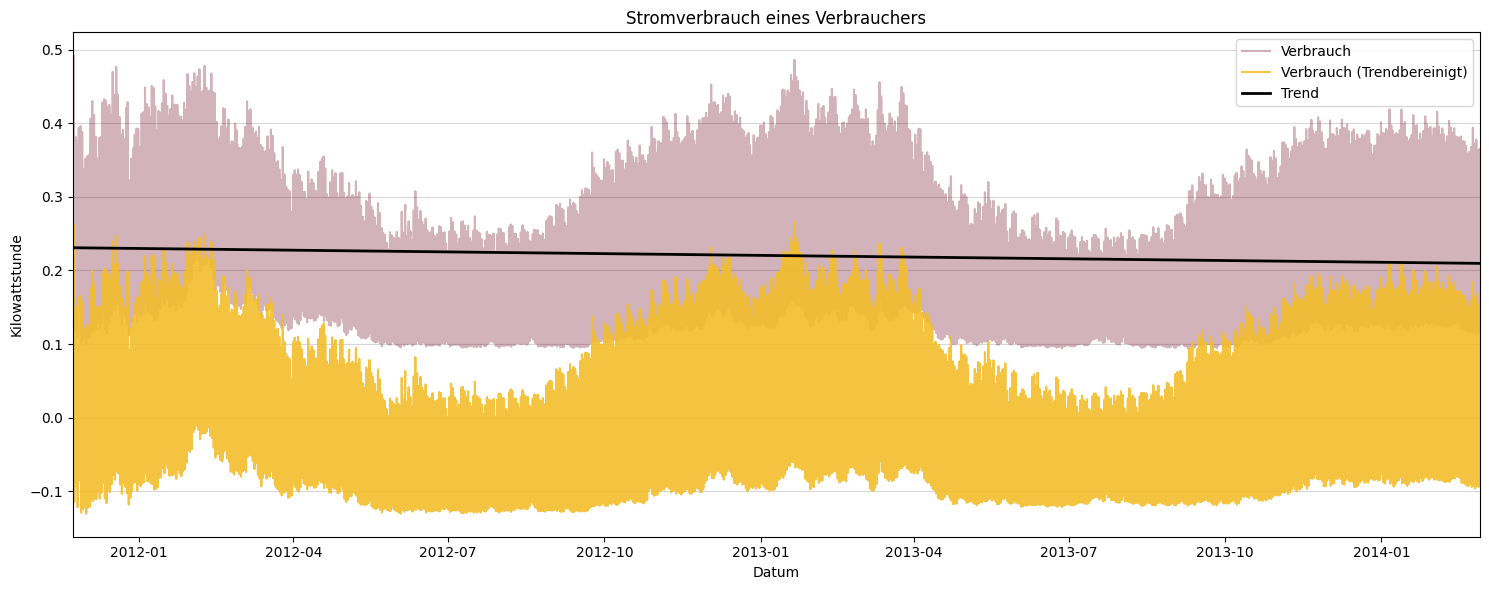

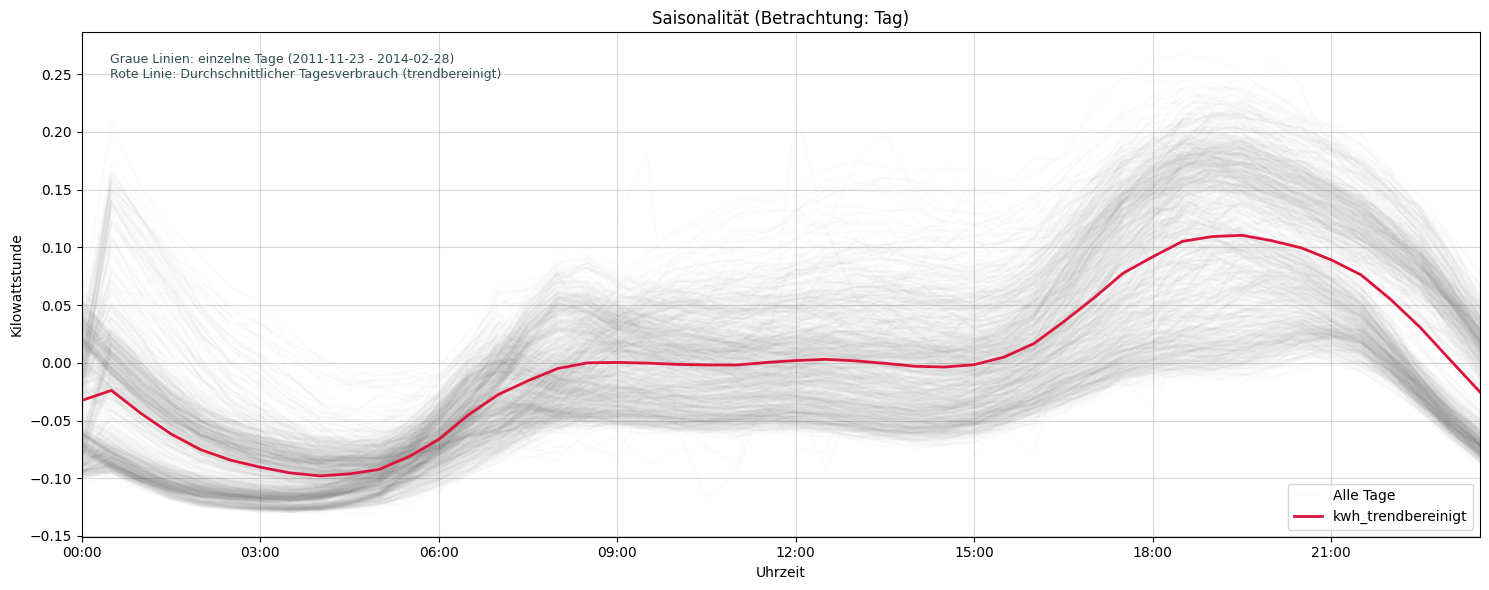

KeyError: 'kwh_bereinigt'

In [24]:
variances(analyse(df_std))

#### Variabler Tarif

In [ ]:
variances(analyse(df_tou))

<font color="orange">
Erkenntnisse: Die größere Varianz der Periodizität lässt vermuten, dass die Haushälte mit variablen Tarif mehr auf die Uhrzeit achten, bei der sie viel Strom verbrauchen.
</font>